# MobileNetV3-Large — Oral Condition Classification (Albert Loh)

Transfer-learning notebook for the ToothPic six-class oral-condition dataset (`calculus`, `caries`, `hypodontia`, `mouth_ulcer`, `normal`, `tooth_discoloration`). It fine-tunes an ImageNet-pretrained **MobileNetV3-Large** on the shared Google Drive dataset, selects the best checkpoint by validation macro-F1, and reports final performance on the held-out test split.

**Flow:** mount Drive → install/import → configure → load pretrained backbone → build class-weighted datasets & loaders → replace the classifier head → fine-tune with a weighted loss, AdamW, cosine LR schedule, and mixed precision → reload the best checkpoint → evaluate on test and save metrics, history, and curves.

Run top-to-bottom in Colab with a GPU runtime. Checkpoints and reports are written to the Drive `models/MobileNetV3_Large/` folder, not to Git.

## 1. Mount Google Drive and locate the dataset

Mounts the Colab user's Drive and points `ROOT` at the shared group folder (each teammate adds it as a shortcut in My Drive). `DATA` is the versioned six-class dataset `dataset/school_oral_training_v1`, already split into `train/`, `val/` and `test/` subfolders per class. The `assert` fails fast with a clear message if the shortcut is missing.

In [ ]:
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

# Each teammate can add the shared folder as a shortcut in My Drive.
ROOT = Path('/content/drive/MyDrive/26S2-AIDL-Group-7-ToothPic')
DATA = ROOT / 'dataset/school_oral_training_v1'
assert (DATA / 'train').exists(), f'Cannot find dataset at {DATA}. Check your Drive shortcut.'
print('Dataset:', DATA)

## 2. Install torchmetrics

`torchmetrics` is not part of the default Colab image. It provides the `F1Score` and `ConfusionMatrix` metrics used during training and test evaluation.

In [ ]:
!pip install torchmetrics

## 3. Imports

Brings in PyTorch and torchvision (pretrained `models` and the v2 `transforms` API), `torchmetrics` for classification metrics, Pillow for image loading, matplotlib/seaborn for plotting, and scikit-learn's `classification_report`. `csv`/`json` are used later to persist training history and final metrics.

In [1]:
import torch
from torch import nn, optim
from torch.utils import data
from torchvision import models
import torchvision.transforms.v2 as transforms
from torchmetrics import classification as metrics

from PIL import Image

import matplotlib.pyplot as plt

from IPython.display import clear_output

from os import listdir, makedirs
import seaborn as sns

import csv, json
from sklearn.metrics import classification_report

## 4. Configuration and hyperparameters

Central place for the run's settings. `DATASET_LABELS` is read from the sorted class subfolders of `train/`, so the label order is fixed and shared by every split. `WORKING_DIR` points at the Drive `models/` folder where checkpoints and reports are written.

Key hyperparameters: `BATCH_SIZE=32`, `EPOCHS=20`, a small AdamW `LEARNING_RATE=1e-4` (suitable for fine-tuning pretrained weights), `SEED=42` for reproducibility, and `DROPOUT_RATE=0.2` for the new classifier head.

In [2]:
DATASET_PATH = DATA
DATASET_LABELS = sorted(listdir(DATASET_PATH + "/train"))
WORKING_DIR = ROOT / 'models'

BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 1e-4

SEED = 42
DROPOUT_RATE = 0.2

## 5. Output directory, random seed, and device

Three small setup steps:

- Create the `MobileNetV3_Large/` output folder under `WORKING_DIR` (idempotent via `exist_ok=True`) so checkpoints and reports have a home.
- Seed PyTorch's RNG (`torch.manual_seed(SEED)`) to make weight init and shuffling reproducible.
- Pick `cuda` when a GPU is available, otherwise fall back to `cpu`, and print which device is in use.

In [3]:
makedirs(f"{WORKING_DIR}/MobileNetV3_Large", exist_ok=True)

In [4]:
torch.manual_seed(SEED)

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("CUDA Available:", torch.cuda.is_available())

CUDA Available: True


## 6. Load the pretrained MobileNetV3-Large backbone

Downloads torchvision's `mobilenet_v3_large` with the `DEFAULT` (ImageNet) weights. This is the transfer-learning starting point: the convolutional feature extractor already knows general visual patterns, and we will adapt it to the six oral-condition classes. The `weights` object also carries the matching input `transforms()` (normalisation statistics) reused below.

In [6]:
weights = models.mobilenet.MobileNet_V3_Large_Weights.DEFAULT
mobilenetv3_model = models.mobilenet_v3_large(weights=weights)
print("MobileNetV3_Large Model Downloaded")

MobileNetV3_Large Model Downloaded


## 7. Dataset class with class weighting

`ToothPicDataset` loads every `.jpg`/`.jpeg` image from each class folder into memory, applying `pre_proc` once at load time and pairing each image with its integer label.

While counting images per class it also computes **inverse-frequency class weights** (`total / (num_classes * count)`). Rare classes get larger weights so the loss does not ignore them — important here because the dataset is imbalanced. These weights are fed to the loss function later.

`__getitem__` applies optional `augmentation` (training only) and then the shared `transforms`, returning `(image, label)`.

In [7]:
class ToothPicDataset(data.Dataset):
    def __init__(self, data_dir, pre_proc, transforms, augmentation=None):
        self.dataset = []
        self.transforms = transforms
        self.augmentation = augmentation
        class_counts = []
        for idx, label in enumerate(DATASET_LABELS):
            num = 0
            for image in listdir(f"{data_dir}/{label}"):
                if image.lower().endswith((".jpg",".jpeg")):
                    self.dataset.append([pre_proc(Image.open(f"{data_dir}/{label}/{image}").convert("RGB")), idx])
                    num += 1
            class_counts.append(num)
        counts_tensor = torch.tensor(class_counts, dtype=torch.float32)
        total_samples = counts_tensor.sum()
        num_classes = len(DATASET_LABELS)
        self.class_weights = total_samples / (num_classes * counts_tensor)

    def __getitem__(self, idx):
        img = self.dataset[idx][0]
        if self.augmentation:
            img = self.augmentation(img)
        img = self.transforms(img)
        label = self.dataset[idx][1]
        return img, label

    def __len__(self):
        return len(self.dataset)

## 8. Transforms, augmentation, and data loaders

Defines the image pipeline in three parts:

- `pre_proc` (applied once at load): convert to a tensor image and resize to 224×224.
- `pre_trans` (applied to every split): cast to float32 in [0,1] and normalise with the pretrained weights' mean/std, so inputs match what the backbone expects.
- `augm_trans` (training only): random horizontal flip and mild brightness/contrast jitter to regularise the model.

Builds `train`/`val`/`test` datasets and `DataLoader`s. Only the training set gets augmentation and shuffling; validation and test use the deterministic pipeline so their metrics are comparable.

In [8]:
trans = weights.transforms()

pre_proc = transforms.Compose([
    transforms.ToImage(),
    transforms.Resize((224, 224)),
])

pre_trans = transforms.Compose([
    transforms.ToDtype(torch.float32, scale=True),   # uint8 → float [0,1]
    transforms.Normalize(mean=trans.mean,
                         std=trans.std),
])

augm_trans = transforms.Compose([
    transforms.RandomHorizontalFlip(0.5),
    transforms.ColorJitter(brightness=0.12, contrast=0.12),
])


train_set = ToothPicDataset(f"{DATASET_PATH}/train/", pre_proc, pre_trans, augm_trans)
train_load = data.DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)

valid_set = ToothPicDataset(f"{DATASET_PATH}/val/", pre_proc, pre_trans)
valid_load = data.DataLoader(valid_set, batch_size=BATCH_SIZE)

test_set = ToothPicDataset(f"{DATASET_PATH}/test/", pre_proc, pre_trans)
test_load = data.DataLoader(test_set, batch_size=BATCH_SIZE)
print("Dataset Loaded")

Dataset Loaded


## 9. Replace the classifier head

The pretrained head outputs 1000 ImageNet classes, so it is swapped for one matching this task: the final `Linear` layer is replaced with `Linear(in_features → len(DATASET_LABELS))` (six outputs), and the preceding dropout is set to `DROPOUT_RATE`.

`requires_grad_(True)` keeps **all** layers trainable — this is full fine-tuning of the backbone plus the new head, not a frozen-feature-extractor approach.

In [9]:
OUT_FEATURES = mobilenetv3_model.classifier[-1].in_features

mobilenetv3_model.classifier[-1] = nn.Linear(OUT_FEATURES, len(DATASET_LABELS))
mobilenetv3_model.classifier[-2]  = nn.Dropout(DROPOUT_RATE)

mobilenetv3_model.requires_grad_(True)  
print("MobileNetV3_Large Classifier Network Added.")


MobileNetV3_Large Classifier Network Added.


## 10. Loss, optimizer, scheduler, and mixed precision

Sets up the training objective and optimisation:

- **Loss:** `CrossEntropyLoss` weighted by the training-set class weights to counter class imbalance.
- **Optimizer:** `AdamW` at `LEARNING_RATE` over all model parameters.
- **Scheduler:** `CosineAnnealingLR` decays the learning rate toward `LEARNING_RATE/100` across the epochs for smoother convergence.
- **AMP:** a `GradScaler` is created when CUDA is available to enable mixed-precision training; the model is moved to the selected device.

In [10]:
loss_function = nn.CrossEntropyLoss(weight=train_set.class_weights.to(device))
optimizer = optim.AdamW(mobilenetv3_model.parameters(), lr=LEARNING_RATE)
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=LEARNING_RATE/100
)
if torch.cuda.is_available():
    scaler = torch.amp.GradScaler(device.type)
mobilenetv3_model.to(device)
print("MobileNetV3_Large Model Loaded")

MobileNetV3_Large Model Loaded


## 11. Training and validation loop

Runs `EPOCHS` epochs, each with a training phase and a validation phase, tracking loss, accuracy, and **macro-F1** for both. Macro-F1 averages per-class F1 equally, so it reflects performance on rare classes rather than being dominated by the majority class.

Each epoch:

- **Train:** forward/backward/step with mixed precision (`autocast` + `GradScaler`) on GPU, or a plain fp32 path on CPU; accumulate loss, correct predictions, and F1.
- **Validate:** `eval()` + `no_grad()` forward pass to compute held-out loss, accuracy, and F1.
- **Checkpoint:** whenever validation macro-F1 improves, save `state_dict` to `mobilenetv3_best.pth` (best-model selection, not last-epoch).
- Step the LR scheduler and append metrics to history lists.
- Redraw a live 3-panel figure (loss / accuracy / macro-F1, train vs validation) using `clear_output`, and print a one-line epoch summary.

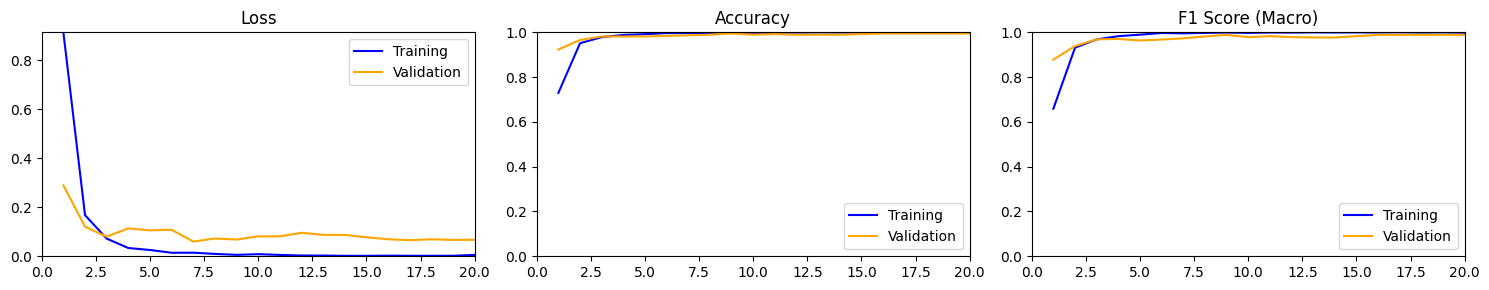

Epoch 20/20 | Train Loss: 0.0057, Acc: 99.84%, F1: 0.9982 | Val Loss: 0.0672, Acc: 99.47%, F1: 0.9887


In [11]:
# Initialize F1 metrics (macro averages equally across all classes; use 'weighted' for class imbalance)
train_f1_metric = metrics.F1Score(task="multiclass", num_classes=len(DATASET_LABELS), average="macro").to(device)
valid_f1_metric = metrics.F1Score(task="multiclass", num_classes=len(DATASET_LABELS), average="macro").to(device)

max_loss = 0
max_f1_macro = 0
training_loss = []
validation_loss = []
training_acc = []
validation_acc = []
training_f1 = []
validation_f1 = []
mobilenetv3_model.eval()

for epoch in range(EPOCHS):
    # Training
    print(f"Epoch {epoch+1}: Training")
    mobilenetv3_model.train()
    train_loss = 0.0
    train_correct = 0

    for image, label in train_load:
        image = image.to(device)
        label = label.to(device)

        optimizer.zero_grad()
        if torch.cuda.is_available():
            with torch.amp.autocast('cuda'):
                output = mobilenetv3_model(image)
                loss = loss_function(output, label)
            scaler.scale(loss).backward()
            scaler.step(optimizer)      # replaces optimizer.step()
            scaler.update()
        else:
            output = mobilenetv3_model(image)
            loss = loss_function(output, label)
            loss.backward()
            optimizer.step()

        train_loss += loss.item() * image.size(0)
        preds = torch.argmax(output, dim=1)
        train_correct += (preds == label).sum().item()
        train_f1_metric.update(preds, label)

    train_epoch_loss = train_loss / len(train_load.dataset)
    train_epoch_acc = train_correct / len(train_load.dataset)
    train_epoch_f1 = train_f1_metric.compute().item()
    train_f1_metric.reset()
    max_loss = max(max_loss, train_epoch_loss)

    # Validation
    print(f"Epoch {epoch+1}: Validating")
    mobilenetv3_model.eval()
    valid_loss = 0.0
    valid_correct = 0

    with torch.no_grad():
        for image, label in valid_load:
            image = image.to(device)
            label = label.to(device)

            if torch.cuda.is_available():
                with torch.amp.autocast(device.type):
                    outputs = mobilenetv3_model(image)
                    loss = loss_function(outputs, label)
            else:
                outputs = mobilenetv3_model(image)
                loss = loss_function(outputs, label)

            valid_loss += loss.item() * image.size(0)
            preds = torch.argmax(outputs, dim=1)
            valid_correct += (preds == label).sum().item()
            valid_f1_metric.update(preds, label)

    valid_epoch_loss = valid_loss / len(valid_load.dataset)
    valid_epoch_acc = valid_correct / len(valid_load.dataset)
    valid_epoch_f1 = valid_f1_metric.compute().item()
    valid_f1_metric.reset()
    max_loss = max(max_loss, valid_epoch_loss)

    if valid_epoch_f1 > max_f1_macro:
        torch.save(mobilenetv3_model.state_dict(), f"{WORKING_DIR}/MobileNetV3_Large/mobilenetv3_best.pth")
    max_f1_macro = max(max_f1_macro, valid_epoch_f1)

    scheduler.step()

    # Record metrics
    training_loss.append(train_epoch_loss)
    validation_loss.append(valid_epoch_loss)
    training_acc.append(train_epoch_acc)
    validation_acc.append(valid_epoch_acc)
    training_f1.append(train_epoch_f1)
    validation_f1.append(valid_epoch_f1)
    epoch_axis = range(1, len(training_loss) + 1)

    # Plotting Loss, Accuracy, and F1 side-by-side
    clear_output(wait=True)
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 3))

    ax1.set_title("Loss")
    ax1.plot(epoch_axis, training_loss, color="blue", label="Training")
    ax1.plot(epoch_axis, validation_loss, color="orange", label="Validation")
    ax1.set_xlim(0, EPOCHS)
    ax1.set_ylim(0, max_loss)
    ax1.legend(loc="upper right")

    ax2.set_title("Accuracy")
    ax2.plot(epoch_axis, training_acc, color="blue", label="Training")
    ax2.plot(epoch_axis, validation_acc, color="orange", label="Validation")
    ax2.set_xlim(0, EPOCHS)
    ax2.set_ylim(0, 1.0)
    ax2.legend(loc="lower right")

    ax3.set_title("F1 Score (Macro)")
    ax3.plot(epoch_axis, training_f1, color="blue", label="Training")
    ax3.plot(epoch_axis, validation_f1, color="orange", label="Validation")
    ax3.set_xlim(0, EPOCHS)
    ax3.set_ylim(0, 1.0)
    ax3.legend(loc="lower right")

    plt.tight_layout()
    plt.show()
    plt.close()

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_epoch_loss:.4f}, Acc: {train_epoch_acc*100:.2f}%, F1: {train_epoch_f1:.4f} | "
        f"Val Loss: {valid_epoch_loss:.4f}, Acc: {valid_epoch_acc*100:.2f}%, F1: {valid_epoch_f1:.4f}"
    )
    # torch.save(mobilenetv3_model.state_dict(), f"{WORKING_DIR}/MobileNetV3_Large/mobilenetv3_epoch_{epoch+1}.pth")


## 12. Reload the best checkpoint

Loads the saved `mobilenetv3_best.pth` weights back into the model. This restores the epoch with the highest validation macro-F1 (rather than the final epoch) so the test evaluation below uses the best-selected model.

In [12]:
mobilenetv3_model.load_state_dict(torch.load(f'{WORKING_DIR}/MobileNetV3_Large/mobilenetv3_best.pth', device))

<All keys matched successfully>

## 13. Test evaluation and reporting

Evaluates the best model on the held-out `test` split (never used for training or model selection) under `eval()` + `no_grad()`, computing loss, accuracy, macro-F1, and a confusion matrix. It then:

- Prints the test metrics and renders a labelled seaborn confusion-matrix heatmap.
- Builds a scikit-learn `classification_report` (per-class precision/recall/F1).
- Writes `metrics.json` (model name, best validation macro-F1 and its epoch, test metrics, full report) and `history.csv` (per-epoch train/val loss and F1) to the output folder.
- Saves a two-panel `training_curves.png` (loss and macro-F1, train vs validation) for comparison with teammates' runs.

Testing | Test Loss: 0.1717, Acc: 98.17%, F1: 0.9652 |


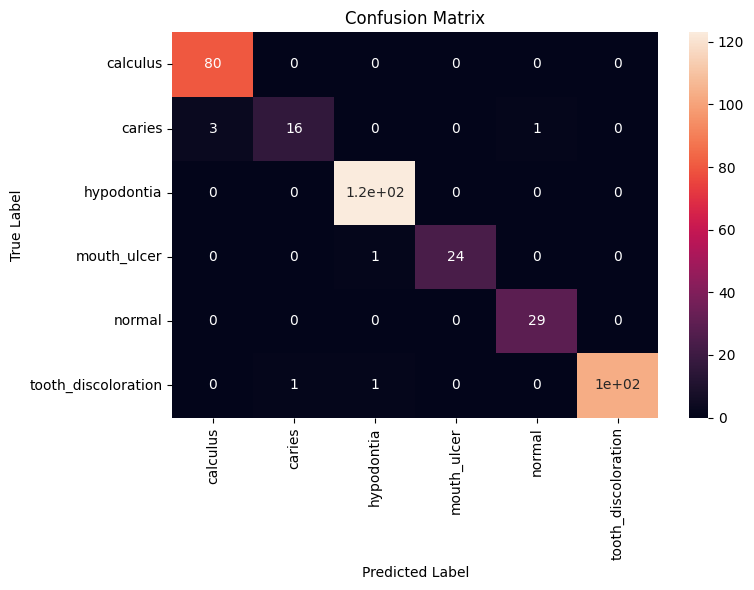

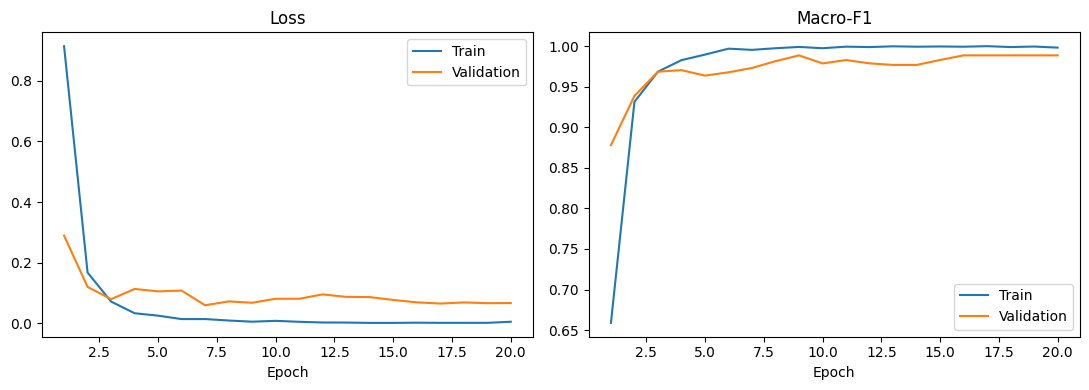

In [13]:
# Load the saved weights and set the model to evaluation mode
mobilenetv3_model.eval()

# Initialize metrics and tracking variables
test_f1_metric = metrics.F1Score(task="multiclass", num_classes=len(DATASET_LABELS), average="macro").to(device)
test_loss = 0.0
test_correct = 0
cm = metrics.ConfusionMatrix(task="multiclass", num_classes=len(DATASET_LABELS)).to(device)
actual, predicted = [], []

# Disable gradient calculation for evaluation
with torch.no_grad():
    for image, label in test_load:  # Changed from valid_load to test_load (verify your loader name!)
        image = image.to(device)
        label = label.to(device)

        if torch.cuda.is_available():
            with torch.amp.autocast(device.type):
                outputs = mobilenetv3_model(image)
                loss = loss_function(outputs, label)
        else:
            outputs = mobilenetv3_model(image)
            loss = loss_function(outputs, label)

        test_loss += loss.item() * image.size(0)
        preds = torch.argmax(outputs, dim=1)
        test_correct += (preds == label).sum().item()
        test_f1_metric.update(preds, label)
        cm.update(preds, label)

        actual.extend(label.cpu().tolist())
        predicted.extend(preds.cpu().tolist())


# Calculate final epoch metrics using the 'test_' variables
test_epoch_loss = test_loss / len(test_load.dataset)
test_epoch_acc = test_correct / len(test_load.dataset)
test_epoch_f1 = test_f1_metric.compute().item()
test_f1_metric.reset()

# Print the final results
print(f"Testing | Test Loss: {test_epoch_loss:.4f}, Acc: {test_epoch_acc*100:.2f}%, F1: {test_epoch_f1:.4f} |")
plt.figure(figsize=(8, 6))
sns.heatmap(cm.compute().cpu(), annot=True,
            xticklabels=DATASET_LABELS, yticklabels=DATASET_LABELS)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

# 5. Reset the metric if you plan to reuse it in the next epoch
cm.reset()

report = classification_report(
    actual, predicted, target_names=DATASET_LABELS,
    output_dict=True, zero_division=0)

best_epoch = int(max(range(len(validation_f1)), key=lambda i: validation_f1[i])) + 1

metrics = {
    "model": "mobilenet_v3_large",
    "best_val_macro_f1": max(validation_f1),
    "best_epoch": best_epoch,
    "test_macro_f1": report["macro avg"]["f1-score"],
    "test_accuracy": report["accuracy"],
    "test_loss": test_epoch_loss,
    "classification_report": report,
}
with open(f"{WORKING_DIR}/MobileNetV3_Large/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

with open(f"{WORKING_DIR}/MobileNetV3_Large/history.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["epoch", "train_loss", "val_loss", "train_f1", "val_f1"])
    for i in range(len(training_loss)):
        w.writerow([i+1, training_loss[i], validation_loss[i],
                    training_f1[i], validation_f1[i]])

# 2-panel curves like your teammate's
ep = range(1, len(training_loss)+1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, training_loss, label="Train")
ax[0].plot(ep, validation_loss, label="Validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(ep, training_f1, label="Train")
ax[1].plot(ep, validation_f1, label="Validation")
ax[1].set_title("Macro-F1"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout()
plt.savefig(f"{WORKING_DIR}/MobileNetV3_Large/training_curves.png", dpi=140)